In [46]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.interpolate import splprep, splev

try:
    from skimage.exposure import rescale_intensity
    from skimage.filters import gaussian
    from skimage.segmentation import active_contour
except ImportError as exc:
    raise ImportError(
        "This notebook requires scikit-image in the current kernel. Install it with `pip install scikit-image`."
    ) from exc

data_dir = Path.cwd()
image_path = data_dir / "PBS 3-MaxIP_with brigthfield.tif"
polyline_path = data_dir / "PBS3_Brightfield_Frame1_Boundary_XY_Coordinates.csv"
spots_path = data_dir / "PBS 3-MaxIP_segmented_spots.csv"


def parse_imagej_description(text):
    metadata = {}
    for line in text.splitlines():
        if "=" in line:
            key, value = line.split("=", 1)
            metadata[key.strip()] = value.strip()
    return metadata


def page_index(channel_idx, time_idx, n_channels):
    return time_idx * n_channels + channel_idx


def load_channel_frame(image_path, channel_idx, time_idx, n_channels):
    with Image.open(image_path) as tif:
        tif.seek(page_index(channel_idx, time_idx, n_channels))
        return np.asarray(tif, dtype=np.float32)


def normalize_for_display(image, vmin=None, vmax=None, lower_percentile=1, upper_percentile=99.5):
    source = image[image > 0]
    if source.size == 0:
        source = image.ravel()

    if vmin is None:
        vmin = float(np.percentile(source, lower_percentile))
    if vmax is None:
        vmax = float(np.percentile(source, upper_percentile))
    if vmax <= vmin:
        vmax = vmin + 1.0

    scaled = np.clip((image - vmin) / (vmax - vmin), 0, 1)
    return scaled, float(vmin), float(vmax)


def preprocess_snake_source(source_image):
    source_nonzero = source_image[source_image > 0]
    source_intensity_range = (
        float(np.percentile(source_nonzero, 1)) if source_nonzero.size else float(source_image.min()),
        float(np.percentile(source_nonzero, 99.5)) if source_nonzero.size else float(source_image.max()),
    )
    snake_ready = rescale_intensity(source_image, in_range=source_intensity_range, out_range=(0.0, 1.0))
    snake_ready = gaussian(snake_ready, sigma=2.0, preserve_range=True)
    return snake_ready


def resample_open_polyline(points_xy, n_points=300, smoothing=0.0):
    tck, _ = splprep([points_xy[:, 0], points_xy[:, 1]], s=smoothing, per=False)
    u = np.linspace(0, 1, n_points, endpoint=True)
    x_new, y_new = splev(u, tck)
    return np.column_stack([x_new, y_new])


with Image.open(image_path) as tif:
    imagej_metadata = parse_imagej_description(str(tif.tag_v2.get(270, "")))
    n_pages = getattr(tif, "n_frames", 1)
    n_channels = int(imagej_metadata.get("channels", 1))
    n_timepoints = int(imagej_metadata.get("frames", max(1, n_pages // max(n_channels, 1))))

    channel_images_t0 = []
    for channel_idx in range(n_channels):
        tif.seek(page_index(channel_idx, 0, n_channels))
        channel_images_t0.append(np.asarray(tif, dtype=np.float32))

channel_images_t0 = np.stack(channel_images_t0, axis=0)
handdrawn_polyline = pd.read_csv(polyline_path)
polyline_xy = handdrawn_polyline[["X", "Y"]].to_numpy(dtype=float)
open_snake_boundary_condition = "free"
initial_snake_xy = resample_open_polyline(polyline_xy, n_points=400, smoothing=0.0)
initial_snake_rc = np.column_stack([initial_snake_xy[:, 1], initial_snake_xy[:, 0]])

# Leave this empty for percentile-based display, or set per-channel FIJI windows like {0: (42, 675)}.
manual_display_windows = {}

channel_display_images = []
channel_display_ranges = []
channel_stats_rows = []

for channel_idx, image in enumerate(channel_images_t0):
    override = manual_display_windows.get(channel_idx)
    if override is None:
        display_image, display_min, display_max = normalize_for_display(image)
    else:
        display_image, display_min, display_max = normalize_for_display(image, *override)

    nonzero = image[image > 0]
    source = nonzero if nonzero.size else image.ravel()
    channel_display_images.append(display_image)
    channel_display_ranges.append((display_min, display_max))
    channel_stats_rows.append(
        {
            "channel": channel_idx,
            "mean_intensity": float(image.mean()),
            "median_intensity": float(np.median(source)),
            "nonzero_fraction": float(np.count_nonzero(image) / image.size),
            "display_min": display_min,
            "display_max": display_max,
        }
    )

channel_display_images = np.stack(channel_display_images, axis=0)
channel_stats = pd.DataFrame(channel_stats_rows).set_index("channel")

# The brightfield / transmitted-light plane is usually the channel with the broader, brighter baseline.
snake_channel_index = int(channel_stats["median_intensity"].idxmax())

if n_channels == 2:
    fluorescence_channel_index = 1 - snake_channel_index
else:
    fluorescence_channel_index = 0

brightfield_display = channel_display_images[snake_channel_index]
fluorescence_display = channel_display_images[fluorescence_channel_index]
composite_rgb = np.dstack(
    [
        np.clip(0.9 * brightfield_display, 0, 1),
        np.clip(0.9 * brightfield_display + fluorescence_display, 0, 1),
        np.clip(0.9 * brightfield_display, 0, 1),
    ]
)

snake_source = channel_images_t0[snake_channel_index]
snake_image = preprocess_snake_source(snake_source)

snake_active_contour_kwargs = dict(
    beta=0.01,
    w_line=4.0,
    w_edge=2.0,
    max_num_iter=2500,
    convergence=0.01,
    boundary_condition=open_snake_boundary_condition,
)

dynamic_anchor_frames = np.array([0, 49, 99, 149, 199, 249], dtype=int)
if dynamic_anchor_frames.max() >= n_timepoints:
    raise ValueError("Dynamic anchor frames exceed the number of available timepoints.")

print(f"ImageJ reports {n_channels} channel(s), {n_timepoints} timepoint(s), and {n_pages} TIFF pages.")
print(f"Selected channel {snake_channel_index} for the active contour; override `snake_channel_index` if FIJI shows a different brightfield order.")
print(
    "Using an open initial spline. Set `open_snake_boundary_condition` to 'fixed' to pin both endpoints, "
    "or use 'free-fixed' / 'fixed-free' to pin only one end."
)
print(f"Dynamic anchor frames (0-based CSV Frame values): {dynamic_anchor_frames.tolist()}")
channel_stats


ImageJ reports 2 channel(s), 289 timepoint(s), and 578 TIFF pages.
Selected channel 1 for the active contour; override `snake_channel_index` if FIJI shows a different brightfield order.
Using an open initial spline. Set `open_snake_boundary_condition` to 'fixed' to pin both endpoints, or use 'free-fixed' / 'fixed-free' to pin only one end.
Dynamic anchor frames (0-based CSV Frame values): [0, 49, 99, 149, 199, 249]


,mean_intensity,median_intensity,nonzero_fraction,display_min,display_max
channel,,,,,
0,87.570877,100.0,0.845308,73.0,185.0
1,125.478096,142.0,0.845308,109.0,222.0


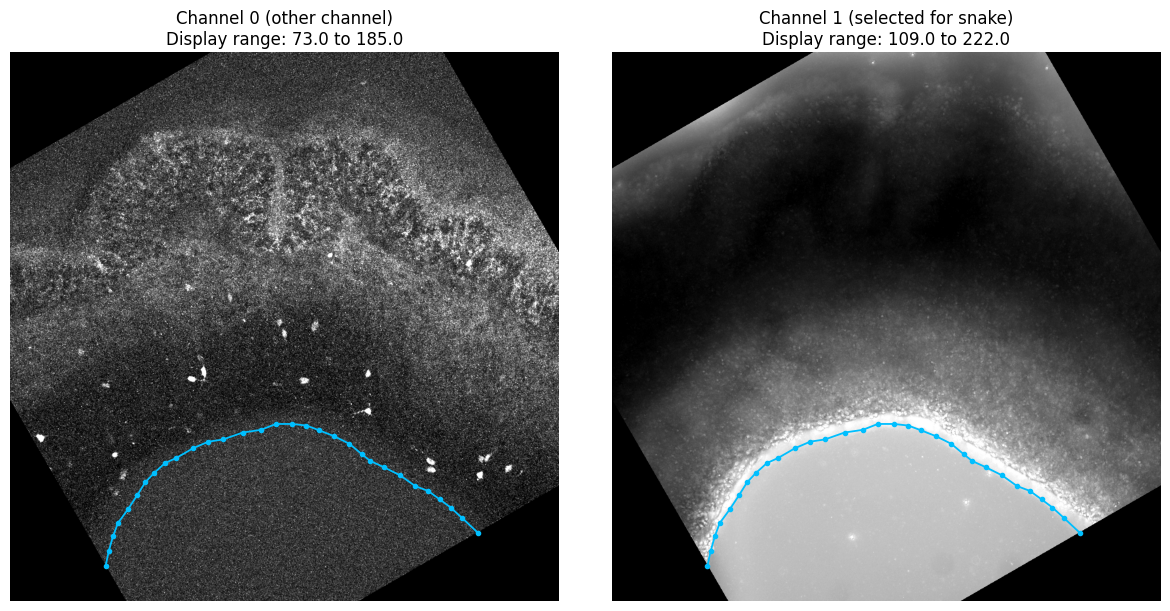

In [47]:
fig, axes = plt.subplots(1, n_channels, figsize=(6 * n_channels, 6), constrained_layout=True)
axes = np.atleast_1d(axes)

for channel_idx, ax in enumerate(axes):
    display_min, display_max = channel_display_ranges[channel_idx]
    role = "selected for snake" if channel_idx == snake_channel_index else "other channel"
    ax.imshow(channel_images_t0[channel_idx], cmap="gray", vmin=display_min, vmax=display_max)
    ax.plot(polyline_xy[:, 0], polyline_xy[:, 1], "-o", color="deepskyblue", linewidth=1.3, markersize=3)
    ax.set_title(f"Channel {channel_idx} ({role})\nDisplay range: {display_min:.1f} to {display_max:.1f}")
    ax.set_axis_off()

plt.show()


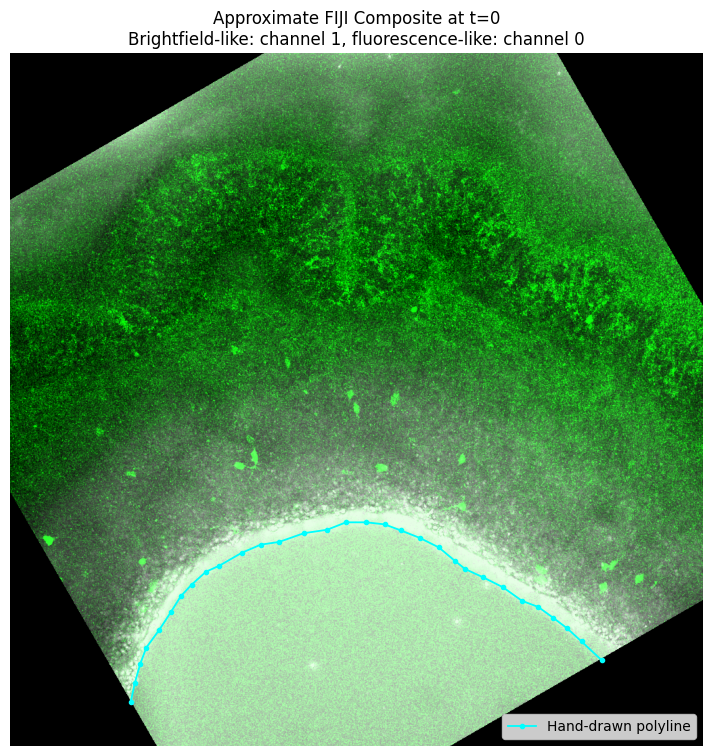

In [48]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(composite_rgb)
ax.plot(polyline_xy[:, 0], polyline_xy[:, 1], "-o", color="cyan", linewidth=1.3, markersize=3, label="Hand-drawn polyline")
ax.set_title(
    f"Approximate FIJI Composite at t=0\nBrightfield-like: channel {snake_channel_index}, fluorescence-like: channel {fluorescence_channel_index}"
)
ax.set_axis_off()
ax.legend(loc="lower right")
plt.show()


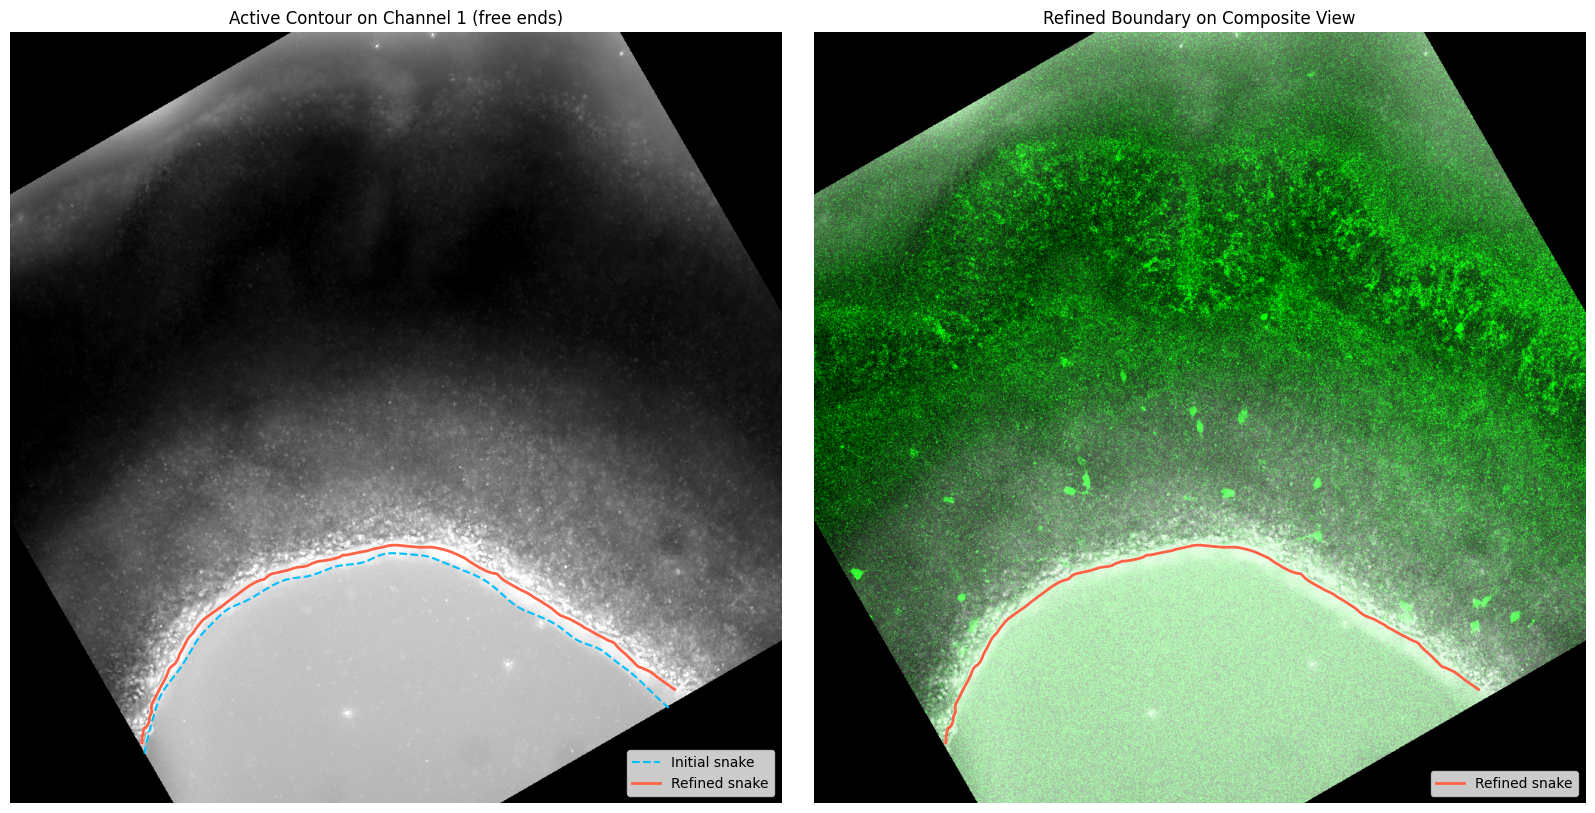

,X,Y
0,175.019989,943.531372
1,174.793137,943.514221
2,174.498352,943.508789
3,174.490402,943.518677
4,174.467194,943.142822


In [49]:
# Static baseline: refine the contour on the first frame only.
refined_snake_rc = active_contour(
    snake_image,
    initial_snake_rc,
    **snake_active_contour_kwargs,
)

refined_snake_xy = np.column_stack([refined_snake_rc[:, 1], refined_snake_rc[:, 0]])
refined_polyline = pd.DataFrame(refined_snake_xy, columns=["X", "Y"])

fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)

display_min, display_max = channel_display_ranges[snake_channel_index]
axes[0].imshow(channel_images_t0[snake_channel_index], cmap="gray", vmin=display_min, vmax=display_max)
axes[0].plot(initial_snake_xy[:, 0], initial_snake_xy[:, 1], "--", color="deepskyblue", linewidth=1.5, label="Initial snake")
axes[0].plot(refined_snake_xy[:, 0], refined_snake_xy[:, 1], "-", color="tomato", linewidth=2.0, label="Refined snake")
axes[0].set_title(f"Active Contour on Channel {snake_channel_index} ({open_snake_boundary_condition} ends)")
axes[0].set_axis_off()
axes[0].legend(loc="lower right")

axes[1].imshow(composite_rgb)
axes[1].plot(refined_snake_xy[:, 0], refined_snake_xy[:, 1], "-", color="tomato", linewidth=2.0, label="Refined snake")
axes[1].set_title("Refined Boundary on Composite View")
axes[1].set_axis_off()
axes[1].legend(loc="lower right")

plt.show()
refined_polyline.head()


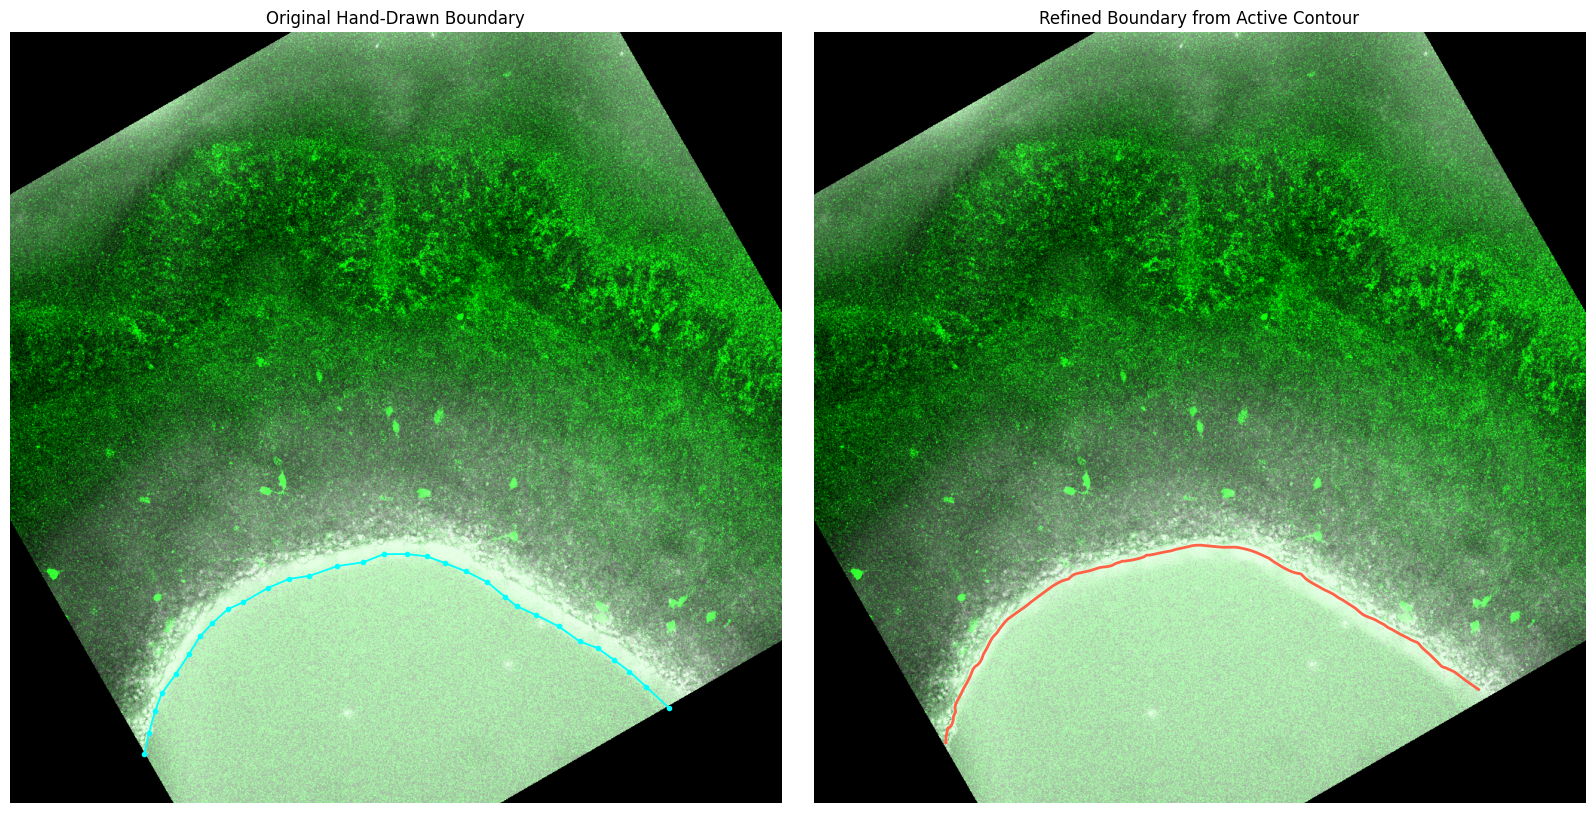

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)

axes[0].imshow(composite_rgb)
axes[0].plot(polyline_xy[:, 0], polyline_xy[:, 1], "-o", color="cyan", linewidth=1.3, markersize=3)
axes[0].set_title("Original Hand-Drawn Boundary")
axes[0].set_axis_off()

axes[1].imshow(composite_rgb)
axes[1].plot(refined_snake_xy[:, 0], refined_snake_xy[:, 1], "-", color="tomato", linewidth=2.0)
axes[1].set_title("Refined Boundary from Active Contour")
axes[1].set_axis_off()

plt.show()


In [51]:
df_spots = pd.read_csv(spots_path, skiprows=[1, 2, 3])


def prepare_curve(curve_xy):
    curve = np.asarray(curve_xy, dtype=float).copy()

    if len(curve) < 2:
        raise ValueError("The boundary polyline needs at least two points.")

    segment_steps = np.linalg.norm(np.diff(curve, axis=0), axis=1)
    curve = curve[np.r_[True, segment_steps > 0]]

    if len(curve) < 2:
        raise ValueError("The boundary polyline collapses to fewer than two unique points.")

    segment_vectors = np.diff(curve, axis=0)
    segment_lengths = np.linalg.norm(segment_vectors, axis=1)
    arc_lengths = np.concatenate([[0.0], np.cumsum(segment_lengths)])
    return curve, arc_lengths


def build_curve_cache(curve_xy):
    curve, arc_lengths = prepare_curve(curve_xy)
    return {"curve": curve, "arc_lengths": arc_lengths}


def point_to_segment(p, a, b):
    ab = b - a
    ab2 = np.dot(ab, ab)
    if ab2 == 0:
        return a.copy(), 0.0

    t = np.dot(p - a, ab) / ab2
    t = np.clip(t, 0.0, 1.0)
    closest = a + t * ab
    return closest, t


def signed_distance_to_polyline(p, curve, arc_lengths):
    best_dist2 = np.inf
    best_closest = None
    best_segment_index = None
    best_t = None

    for i in range(len(curve) - 1):
        a, b = curve[i], curve[i + 1]
        closest, t = point_to_segment(p, a, b)
        diff = p - closest
        dist2 = np.dot(diff, diff)

        if dist2 < best_dist2:
            best_dist2 = dist2
            best_closest = closest
            best_segment_index = i
            best_t = t

    a = curve[best_segment_index]
    b = curve[best_segment_index + 1]
    tangent = b - a
    tangent = tangent / np.linalg.norm(tangent)
    normal = np.array([-tangent[1], tangent[0]])

    offset = p - best_closest
    dot = np.dot(offset, normal)
    sign = -1.0 if dot > 0 else 1.0 if dot < 0 else 0.0

    signed_distance = sign * np.sqrt(best_dist2)
    s = arc_lengths[best_segment_index] + best_t * np.linalg.norm(b - a)
    return signed_distance, best_closest, best_segment_index, s


def measure_points_against_curve(points_xy, curve_cache):
    if len(points_xy) == 0:
        return np.empty((0, 4), dtype=object)

    return np.array(
        [signed_distance_to_polyline(p, curve_cache["curve"], curve_cache["arc_lengths"]) for p in points_xy],
        dtype=object,
    )


static_curve_cache = build_curve_cache(refined_snake_xy)
static_curve = static_curve_cache["curve"]
spot_xy = df_spots[["X", "Y"]].to_numpy(dtype=float)

static_results = measure_points_against_curve(spot_xy, static_curve_cache)
static_closest_boundary_xy = np.vstack(static_results[:, 1])

df_spots["signed_distance_to_boundary"] = static_results[:, 0].astype(float)
df_spots["closest_boundary_x"] = static_closest_boundary_xy[:, 0]
df_spots["closest_boundary_y"] = static_closest_boundary_xy[:, 1]
df_spots["closest_boundary_segment"] = static_results[:, 2].astype(int)
df_spots["boundary_arc_length"] = static_results[:, 3].astype(float)

# If the sign is flipped relative to your biological convention, reverse `static_curve`
# or multiply `signed_distance_to_boundary` by -1 after inspecting a few points.
df_spots[["Spot ID", "Frame", "X", "Y", "signed_distance_to_boundary", "boundary_arc_length"]].head()


,Spot ID,Frame,X,Y,signed_distance_to_boundary,boundary_arc_length
0,142978,53,576.603499,503.555788,181.088839,517.183376
1,141059,41,576.348688,504.868640,179.757548,517.183376
2,141955,46,577.362216,504.690650,180.034714,517.183376
3,143495,60,577.230069,500.026576,184.662308,517.183376
4,138757,12,575.399692,507.203310,177.344045,517.183376


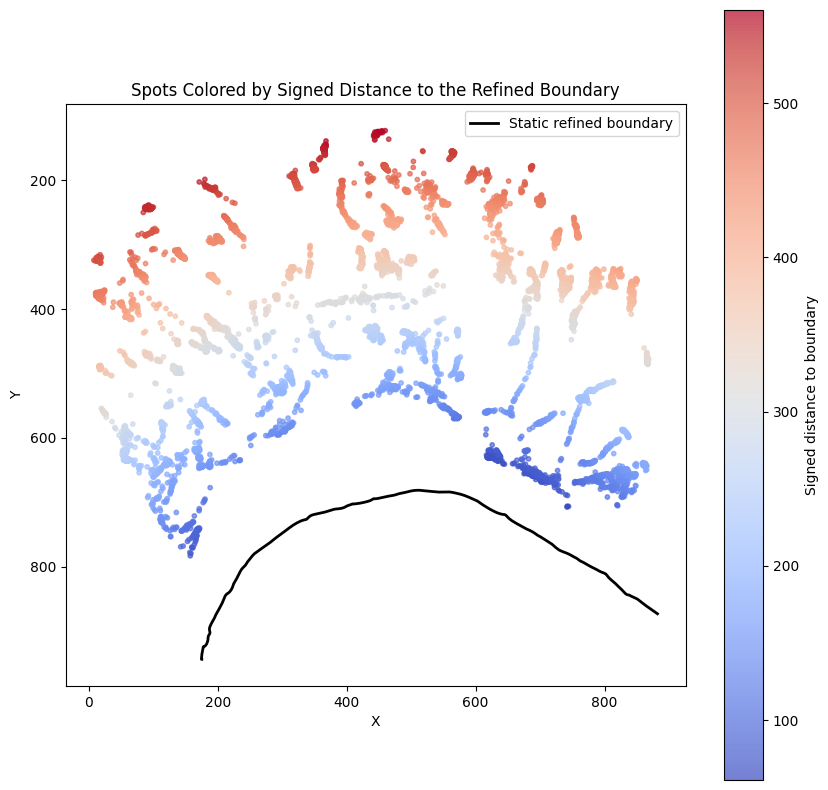

In [52]:
fig, ax = plt.subplots(figsize=(10, 10))
scatter = ax.scatter(
    df_spots["X"],
    df_spots["Y"],
    c=df_spots["signed_distance_to_boundary"],
    s=10,
    cmap="coolwarm",
    alpha=0.7,
)
ax.plot(static_curve[:, 0], static_curve[:, 1], color="black", linewidth=2.0, label="Static refined boundary")
ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_title("Spots Colored by Signed Distance to the Refined Boundary")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.legend(loc="best")
plt.colorbar(scatter, ax=ax, label="Signed distance to boundary")
plt.show()


In [53]:

def assign_dynamic_anchor_frame(frame_value, anchor_frames):
    diffs = np.abs(anchor_frames - frame_value)
    min_diff = diffs.min()
    # Later-anchor tie breaking: if two anchors are equally close, choose the later one.
    return int(anchor_frames[diffs == min_diff][-1])


dynamic_anchor_curves = {0: refined_snake_xy.copy()}
dynamic_anchor_curve_caches = {0: build_curve_cache(refined_snake_xy)}
previous_anchor_snake_rc = refined_snake_rc.copy()

for anchor_frame in dynamic_anchor_frames[1:]:
    anchor_source = load_channel_frame(image_path, snake_channel_index, anchor_frame, n_channels)
    anchor_image = preprocess_snake_source(anchor_source)
    anchor_snake_rc = active_contour(
        anchor_image,
        previous_anchor_snake_rc,
        **snake_active_contour_kwargs,
    )
    anchor_snake_xy = np.column_stack([anchor_snake_rc[:, 1], anchor_snake_rc[:, 0]])
    dynamic_anchor_curves[anchor_frame] = anchor_snake_xy
    dynamic_anchor_curve_caches[anchor_frame] = build_curve_cache(anchor_snake_xy)
    previous_anchor_snake_rc = anchor_snake_rc

df_spots_dynamic = df_spots.copy()
spot_anchor_frames = np.array(
    [assign_dynamic_anchor_frame(frame_value, dynamic_anchor_frames) for frame_value in df_spots_dynamic["Frame"].to_numpy(dtype=int)],
    dtype=int,
)

dynamic_signed_distance = np.full(len(df_spots_dynamic), np.nan, dtype=float)
dynamic_closest_boundary_xy = np.full((len(df_spots_dynamic), 2), np.nan, dtype=float)
dynamic_closest_boundary_segment = np.full(len(df_spots_dynamic), -1, dtype=int)
dynamic_boundary_arc_length = np.full(len(df_spots_dynamic), np.nan, dtype=float)

for anchor_frame in dynamic_anchor_frames:
    mask = spot_anchor_frames == anchor_frame
    anchor_points = df_spots_dynamic.loc[mask, ["X", "Y"]].to_numpy(dtype=float)
    anchor_results = measure_points_against_curve(anchor_points, dynamic_anchor_curve_caches[anchor_frame])
    if len(anchor_results) == 0:
        continue

    dynamic_signed_distance[mask] = anchor_results[:, 0].astype(float)
    dynamic_closest_boundary_xy[mask] = np.vstack(anchor_results[:, 1])
    dynamic_closest_boundary_segment[mask] = anchor_results[:, 2].astype(int)
    dynamic_boundary_arc_length[mask] = anchor_results[:, 3].astype(float)

df_spots_dynamic["dynamic_anchor_frame"] = spot_anchor_frames
df_spots_dynamic["dynamic_signed_distance_to_boundary"] = dynamic_signed_distance
df_spots_dynamic["dynamic_closest_boundary_x"] = dynamic_closest_boundary_xy[:, 0]
df_spots_dynamic["dynamic_closest_boundary_y"] = dynamic_closest_boundary_xy[:, 1]
df_spots_dynamic["dynamic_closest_boundary_segment"] = dynamic_closest_boundary_segment
df_spots_dynamic["dynamic_boundary_arc_length"] = dynamic_boundary_arc_length

if df_spots_dynamic[
    [
        "dynamic_signed_distance_to_boundary",
        "dynamic_closest_boundary_x",
        "dynamic_closest_boundary_y",
        "dynamic_boundary_arc_length",
    ]
].isna().any().any():
    raise ValueError("Dynamic boundary measurement left missing values in the spot table.")

dynamic_anchor_summary = pd.DataFrame(
    {
        "anchor_frame": dynamic_anchor_frames,
        "contour_point_count": [len(dynamic_anchor_curve_caches[anchor_frame]["curve"]) for anchor_frame in dynamic_anchor_frames],
        "spot_count": [int((spot_anchor_frames == anchor_frame).sum()) for anchor_frame in dynamic_anchor_frames],
    }
)

dynamic_anchor_assignment_check = pd.DataFrame(
    {
        "frame": [0, 24, 25, 73, 74, 123, 124, 173, 174, 223, 224, 288],
    }
)
dynamic_anchor_assignment_check["assigned_anchor_frame"] = dynamic_anchor_assignment_check["frame"].apply(
    lambda frame_value: assign_dynamic_anchor_frame(frame_value, dynamic_anchor_frames)
)

print("Computed dynamic anchor contours:", dynamic_anchor_frames.tolist())
print("Spot-to-anchor assignment checks:")
dynamic_anchor_assignment_check


Computed dynamic anchor contours: [0, 49, 99, 149, 199, 249]
Spot-to-anchor assignment checks:


,frame,assigned_anchor_frame
0,0,0
1,24,0
2,25,49
3,73,49
4,74,99
5,123,99
6,124,149
7,173,149
8,174,199
9,223,199


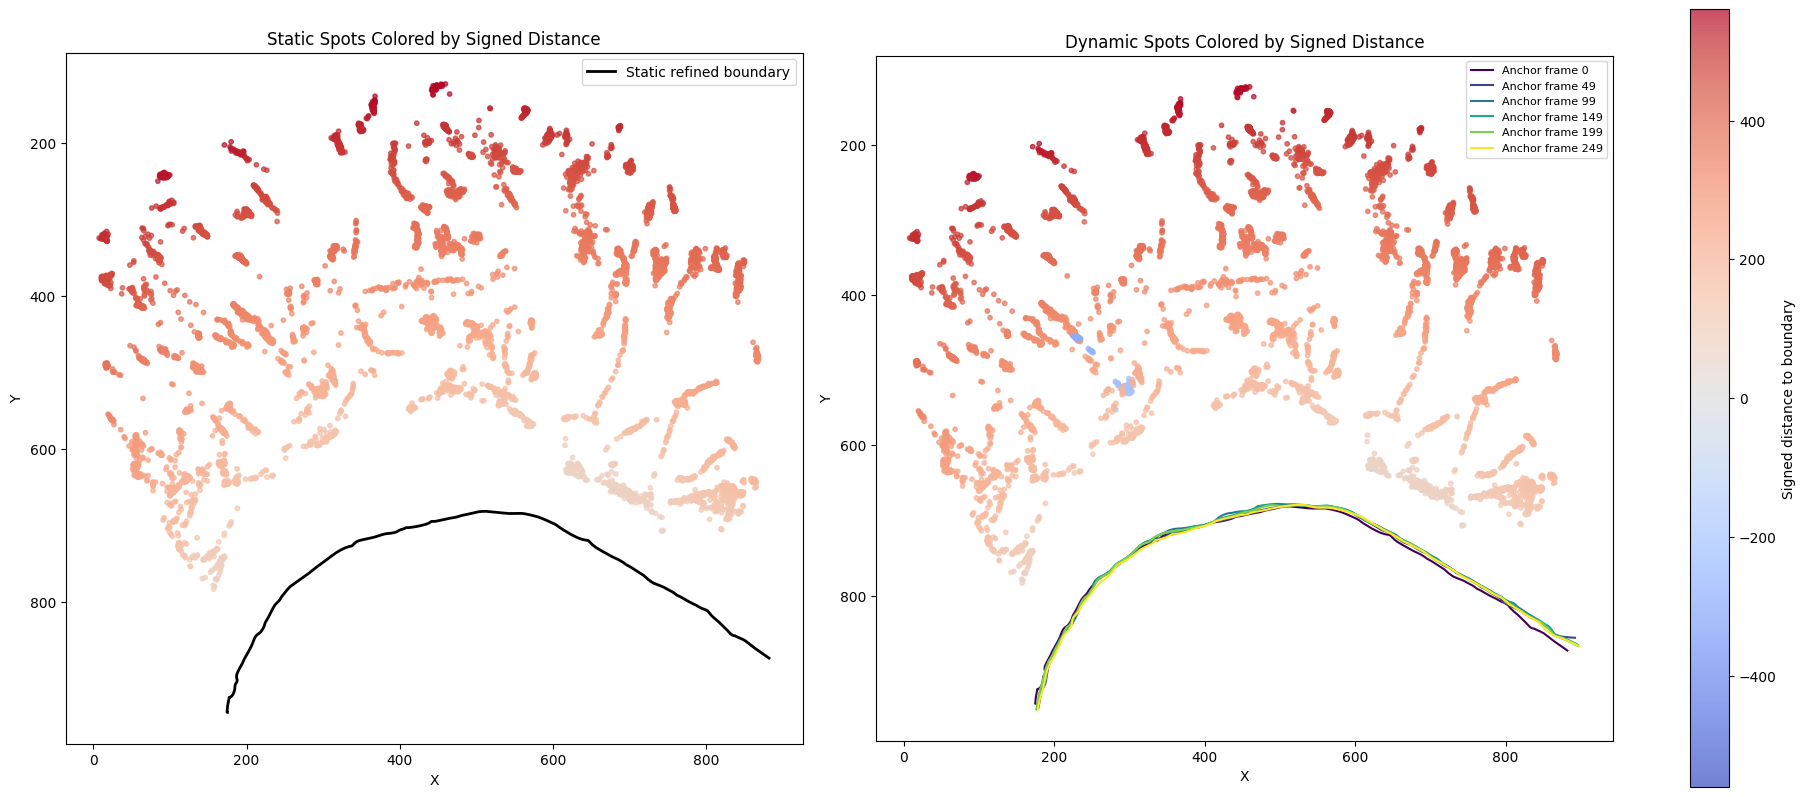

In [54]:
combined_distances = np.concatenate(
    [
        df_spots["signed_distance_to_boundary"].to_numpy(dtype=float),
        df_spots_dynamic["dynamic_signed_distance_to_boundary"].to_numpy(dtype=float),
    ]
)
color_limit = float(np.nanmax(np.abs(combined_distances)))

fig, axes = plt.subplots(1, 2, figsize=(18, 8), constrained_layout=True)

static_scatter = axes[0].scatter(
    df_spots["X"],
    df_spots["Y"],
    c=df_spots["signed_distance_to_boundary"],
    s=10,
    cmap="coolwarm",
    alpha=0.7,
    vmin=-color_limit,
    vmax=color_limit,
)
axes[0].plot(static_curve[:, 0], static_curve[:, 1], color="black", linewidth=2.0, label="Static refined boundary")
axes[0].set_aspect("equal")
axes[0].invert_yaxis()
axes[0].set_title("Static Spots Colored by Signed Distance")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].legend(loc="best")

dynamic_scatter = axes[1].scatter(
    df_spots_dynamic["X"],
    df_spots_dynamic["Y"],
    c=df_spots_dynamic["dynamic_signed_distance_to_boundary"],
    s=10,
    cmap="coolwarm",
    alpha=0.7,
    vmin=-color_limit,
    vmax=color_limit,
)
dynamic_line_colors = plt.cm.viridis(np.linspace(0, 1, len(dynamic_anchor_frames)))
for line_color, anchor_frame in zip(dynamic_line_colors, dynamic_anchor_frames):
    dynamic_curve = dynamic_anchor_curve_caches[anchor_frame]["curve"]
    axes[1].plot(
        dynamic_curve[:, 0],
        dynamic_curve[:, 1],
        color=line_color,
        linewidth=1.5,
        label=f"Anchor frame {anchor_frame}",
    )
axes[1].set_aspect("equal")
axes[1].invert_yaxis()
axes[1].set_title("Dynamic Spots Colored by Signed Distance")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
axes[1].legend(loc="best", fontsize=8)

fig.colorbar(dynamic_scatter, ax=axes, label="Signed distance to boundary")
plt.show()


In [ ]:
n_lowest_dynamic_spots = 20

lowest_dynamic_signed_distance_spots = (
    df_spots_dynamic[
        [
            "Spot ID",
            "Track ID",
            "Frame",
            "dynamic_anchor_frame",
            "X",
            "Y",
            "dynamic_signed_distance_to_boundary",
            "dynamic_boundary_arc_length",
            "dynamic_closest_boundary_x",
            "dynamic_closest_boundary_y",
        ]
    ]
    .sort_values("dynamic_signed_distance_to_boundary", ascending=True)
    .head(n_lowest_dynamic_spots)
    .reset_index(drop=True)
)

lowest_dynamic_signed_distance_spots

# The signed

,Spot ID,Track ID,Frame,dynamic_anchor_frame,X,Y,dynamic_signed_distance_to_boundary,dynamic_boundary_arc_length,dynamic_closest_boundary_x,dynamic_closest_boundary_y
0,145262,17,70,49,222.773752,450.801730,-293.750155,288.702702,334.068542,722.6521
1,145335,17,71,49,223.731799,452.428271,-291.882022,288.702702,334.068542,722.6521
2,144730,17,69,49,224.456078,453.791947,-290.345783,288.702702,334.068542,722.6521
3,144566,17,68,49,224.514425,454.236381,-289.912232,288.702702,334.068542,722.6521
4,141946,17,45,49,226.430129,454.482644,-288.965197,288.702702,334.068542,722.6521
5,141291,17,38,49,226.268921,455.005895,-288.539857,288.702702,334.068542,722.6521
6,142798,17,52,49,226.651175,455.364153,-288.064815,288.702702,334.068542,722.6521
7,141868,17,47,49,228.568121,454.750843,-287.926071,288.702702,334.068542,722.6521
8,141518,17,43,49,227.039512,455.377342,-287.907988,288.702702,334.068542,722.6521
9,140897,17,37,49,226.603559,455.604300,-287.859775,288.702702,334.068542,722.6521
